In [41]:
import sys
import os
import numpy as np
import pandas as pd


sys.path.append(os.path.join(os.getcwd(), '../../src'))
from utils_robot import generate_utils
from utils_robot import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from models import hgm
from models import bom

In [42]:
import importlib
importlib.reload(generate_utils)
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/models/hgm.py'>

In [43]:
file_id = 19

weights = (0.1, -0.25, 1.)

neuron_labels = [f'N{i}' for i in range(20)]
bhl_selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

In [44]:
path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')

# read
(filename_gcamp,
 discrete_states, eigenworms) = read_utils.get_data(path, file_id)

# clear nan values
mask = eigenworms.notna().all(axis=1)

eigenworms = eigenworms[mask]
discrete_states = discrete_states[mask]

# preprocess
pass

In [45]:
# generate
(filename,
 modes,
 traces_reconstructed,
 traces_residual,
 traces,
 params,
 params_manifold) = generate_utils.artificialize(weights, 'hgm',
												 filename_gcamp,
												 neuron_labels,
												 eigenworms,
												 discrete_states[bhl_selection],
												 n_dimensions=len(bhl_selection))

In [46]:
neuron_labels = neuron_labels[:5]

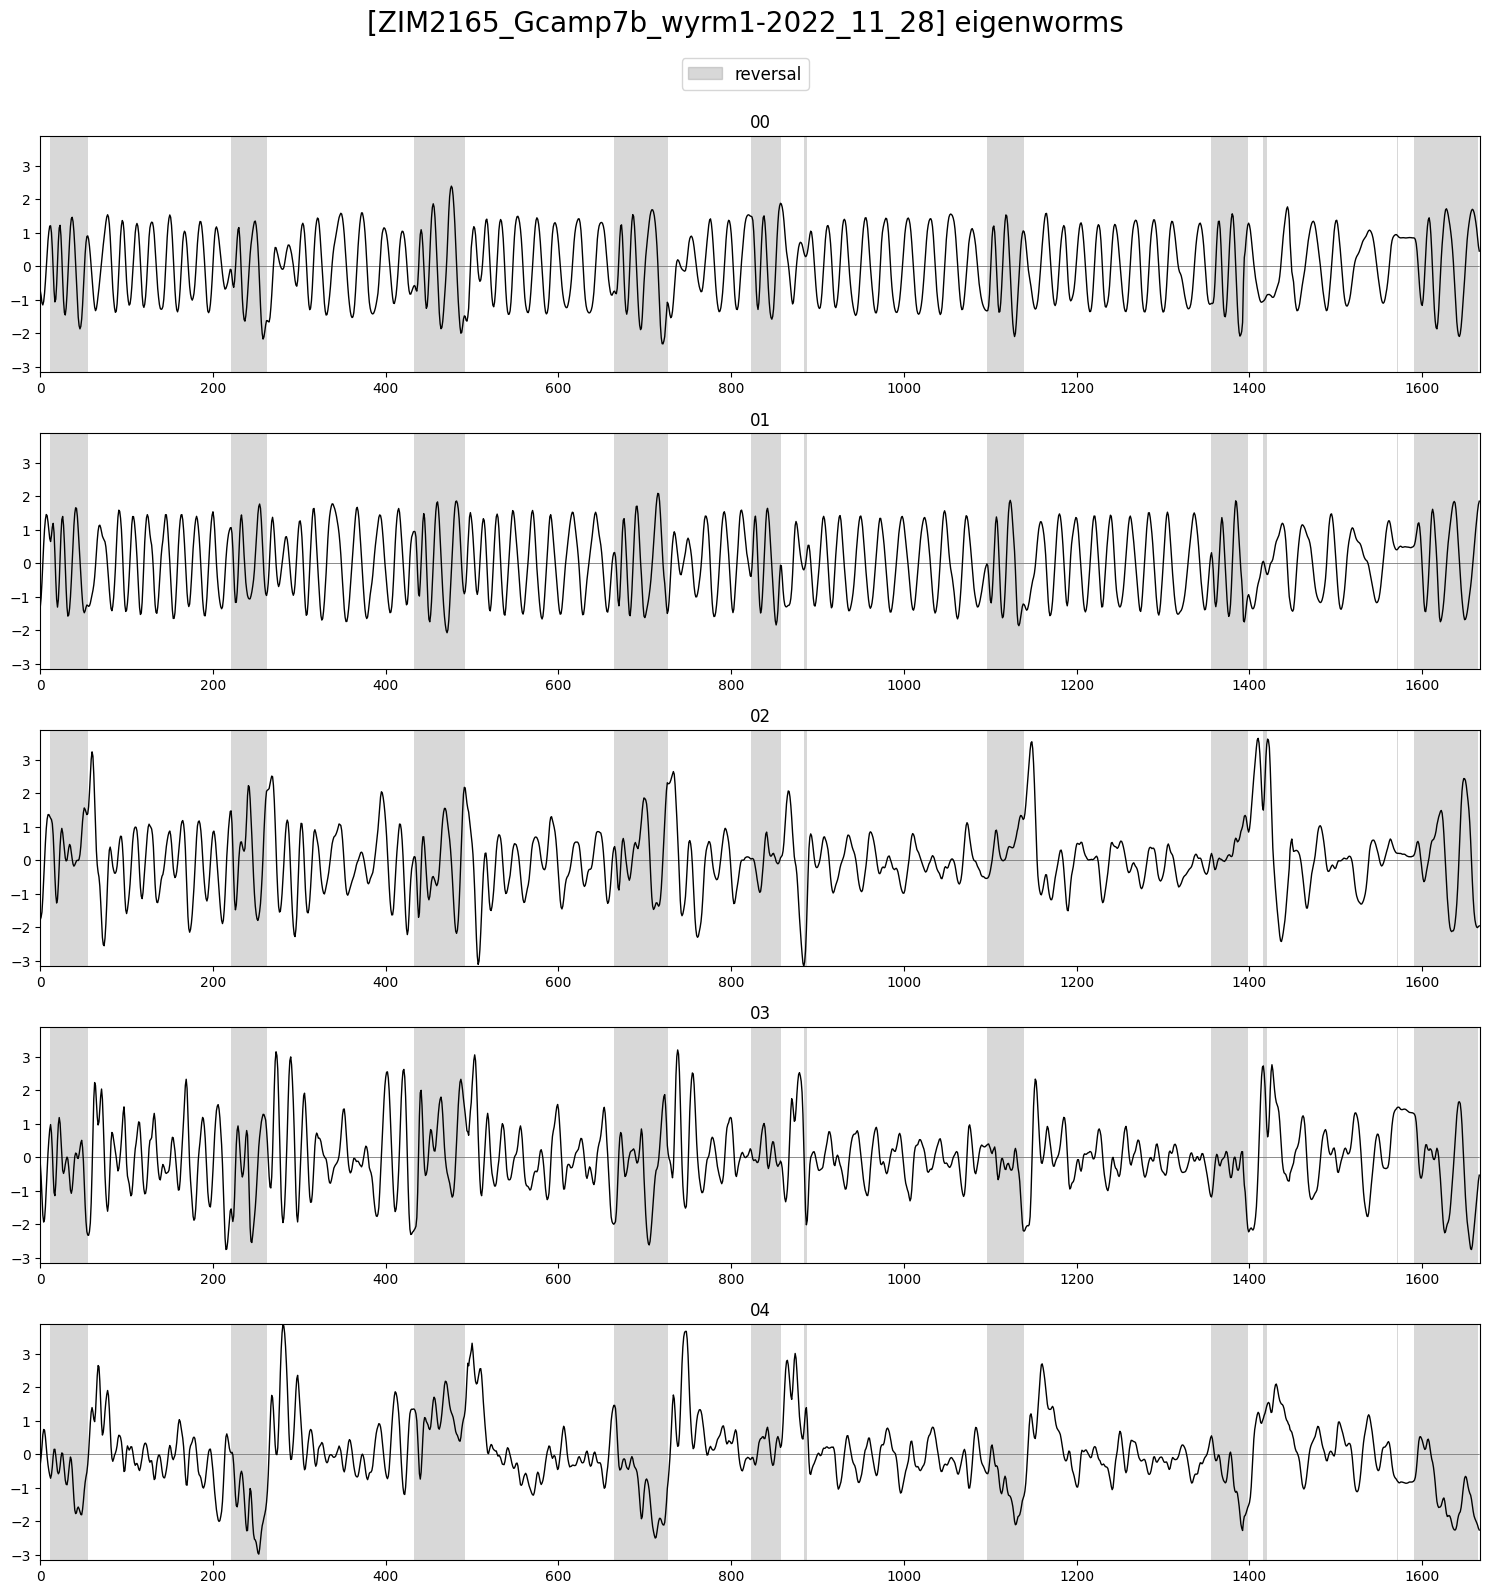

In [47]:
plot_utils.plot_traces(eigenworms,
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] eigenworms', ylimits=None, plots_per_row=1)

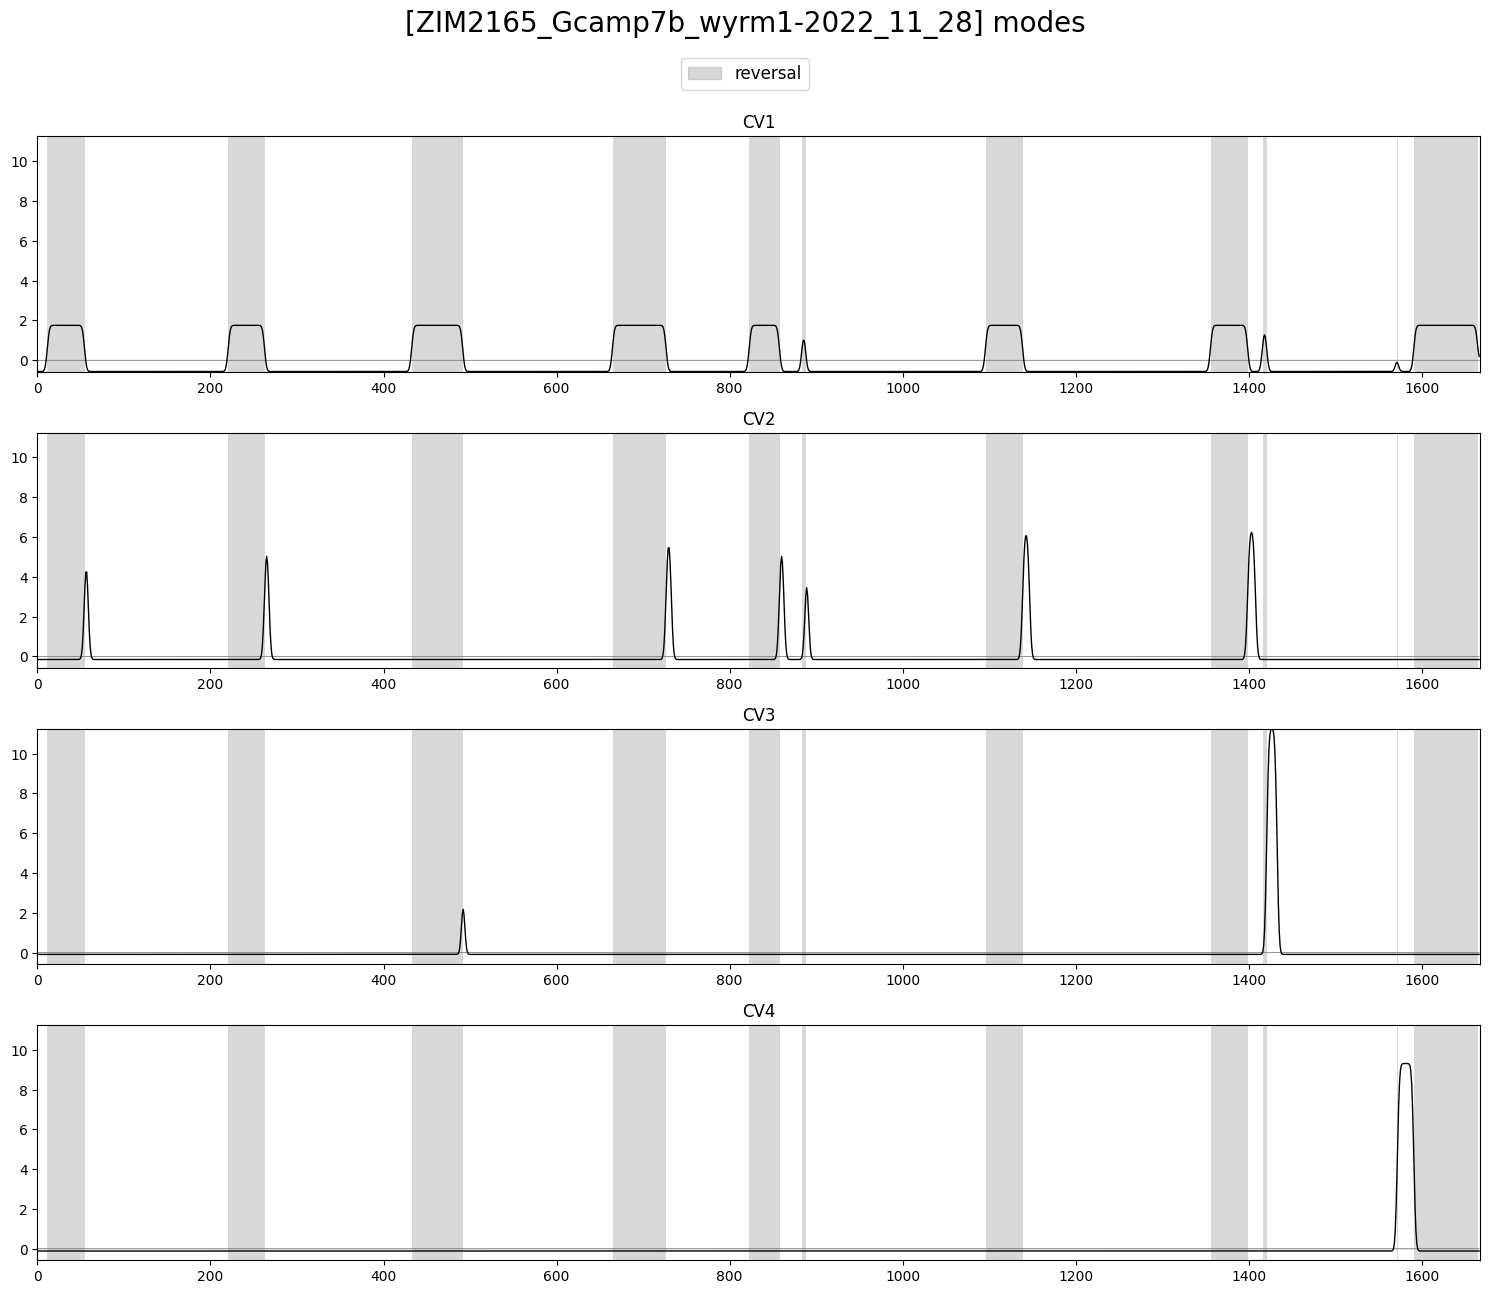

In [48]:
plot_utils.plot_traces(modes,
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] modes', ylimits=None, plots_per_row=1)

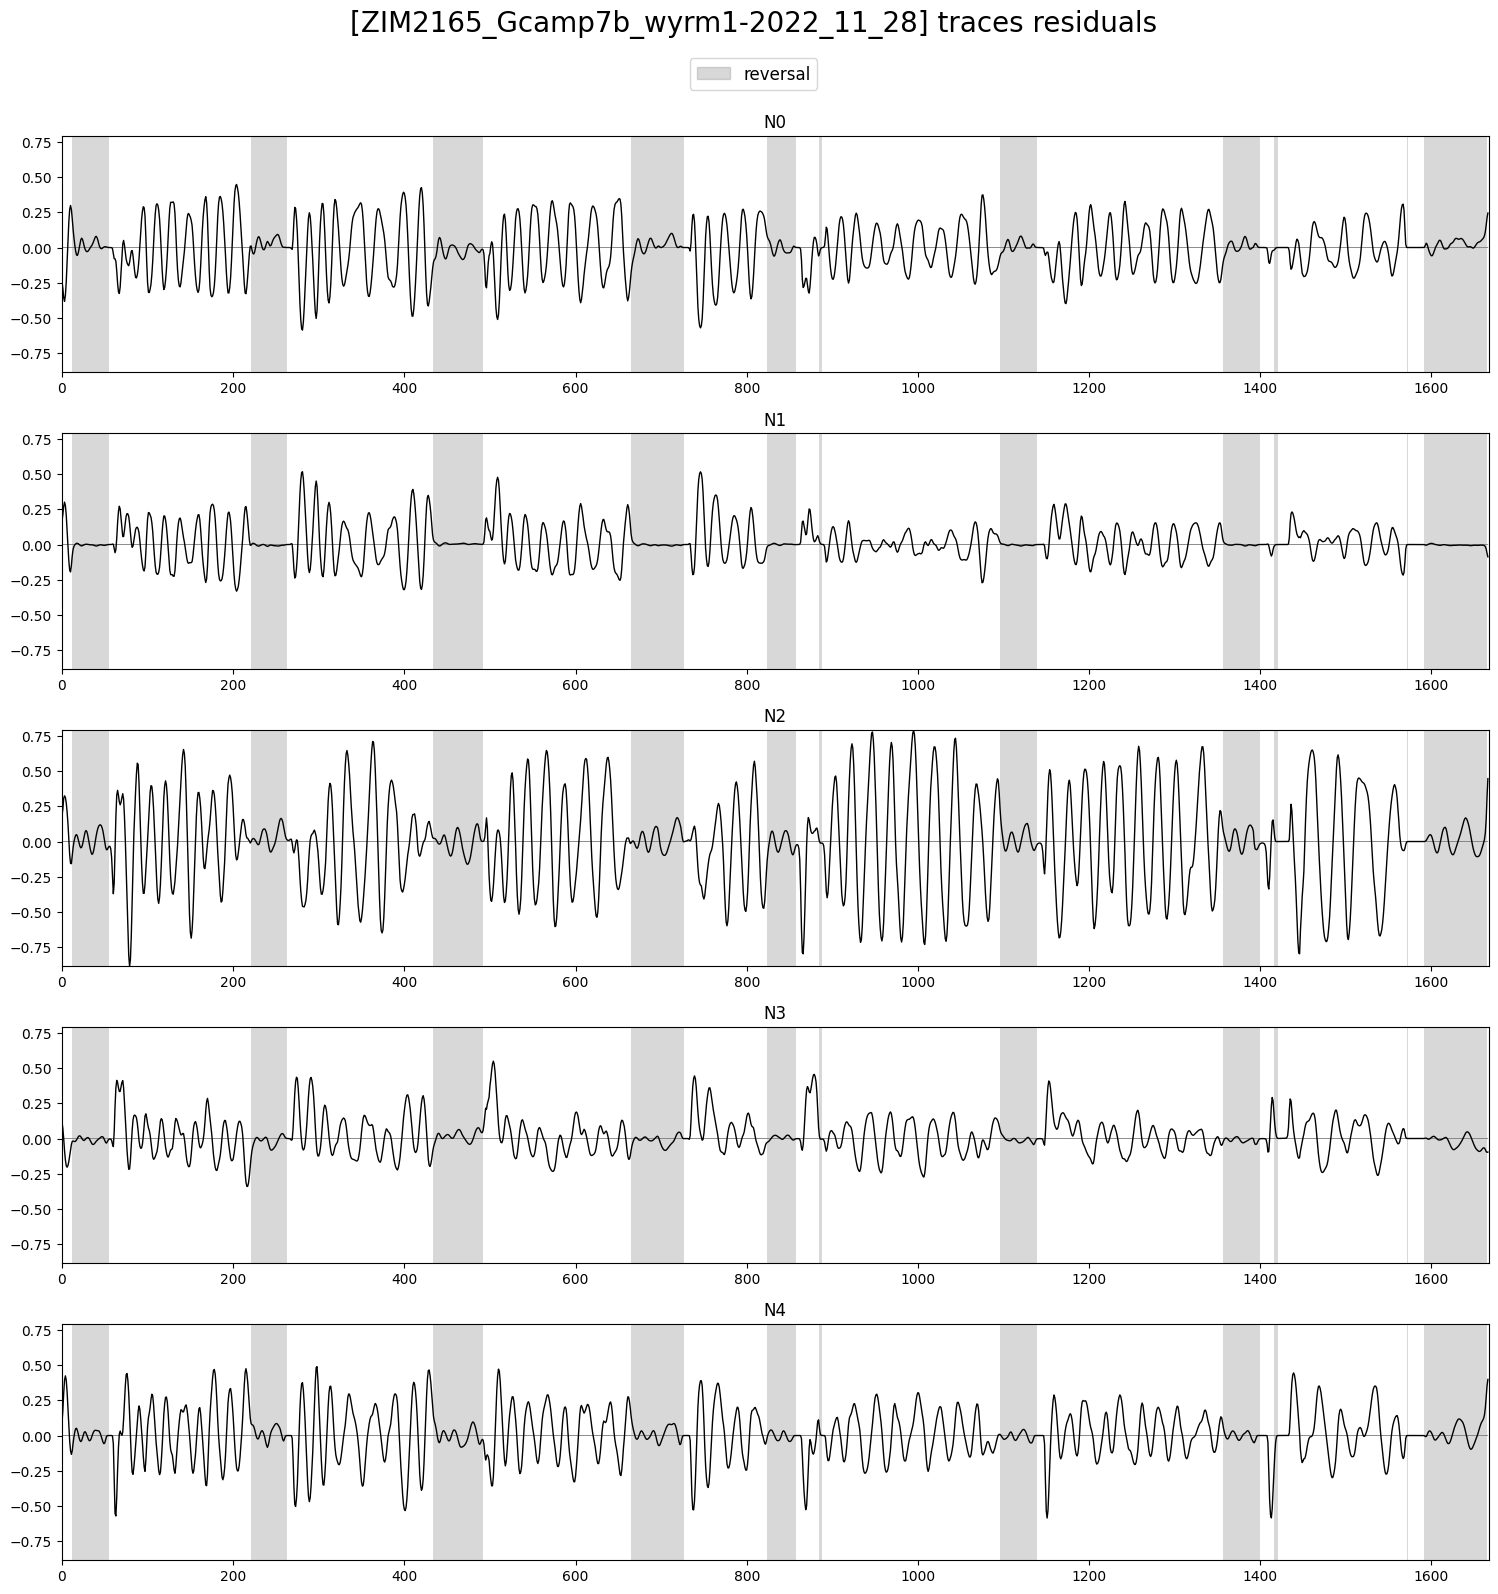

In [49]:
plot_utils.plot_traces(traces_residual[neuron_labels],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] traces residuals', ylimits=None, plots_per_row=1)

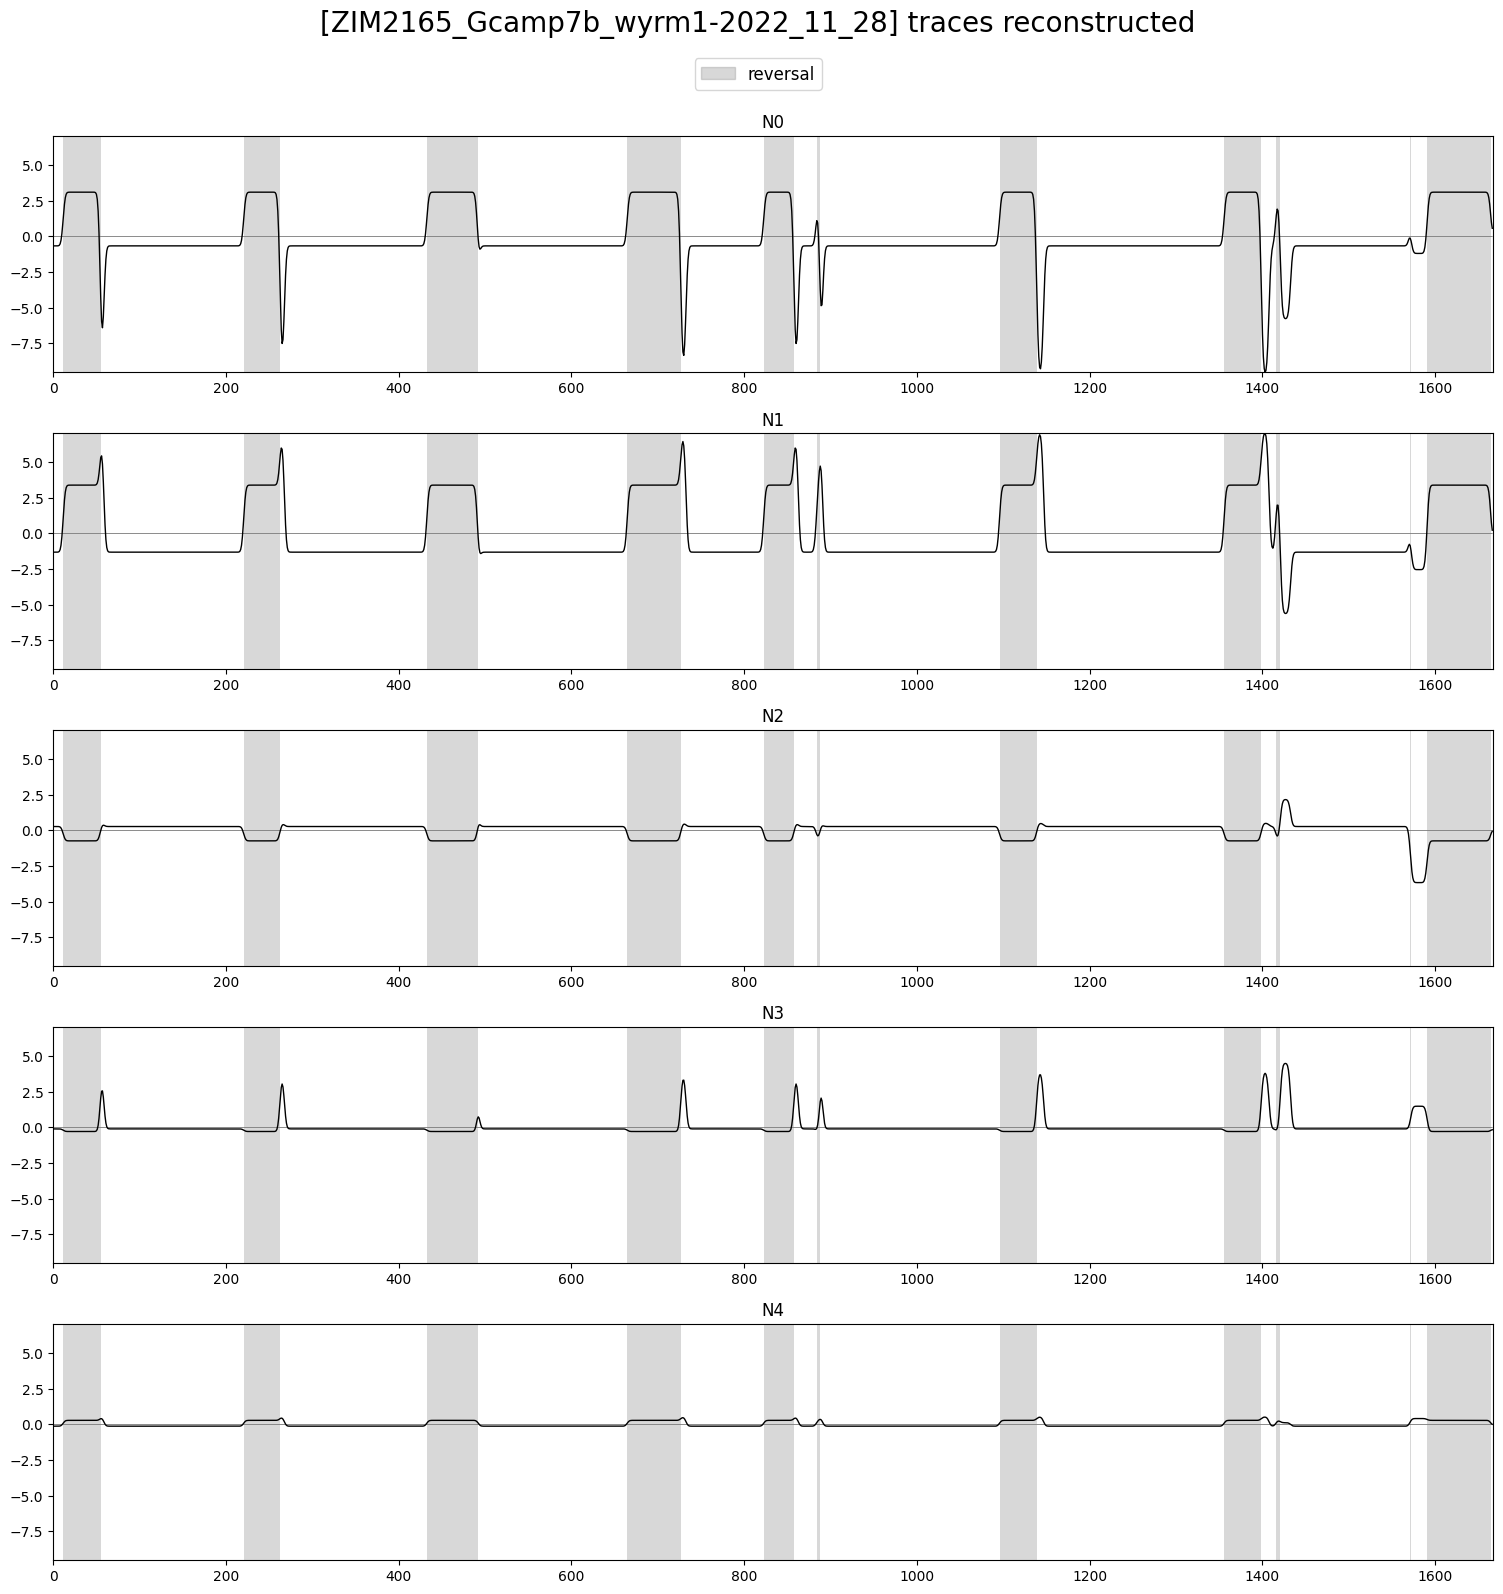

In [50]:
plot_utils.plot_traces(traces_reconstructed[neuron_labels],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] traces reconstructed', ylimits=None, plots_per_row=1)

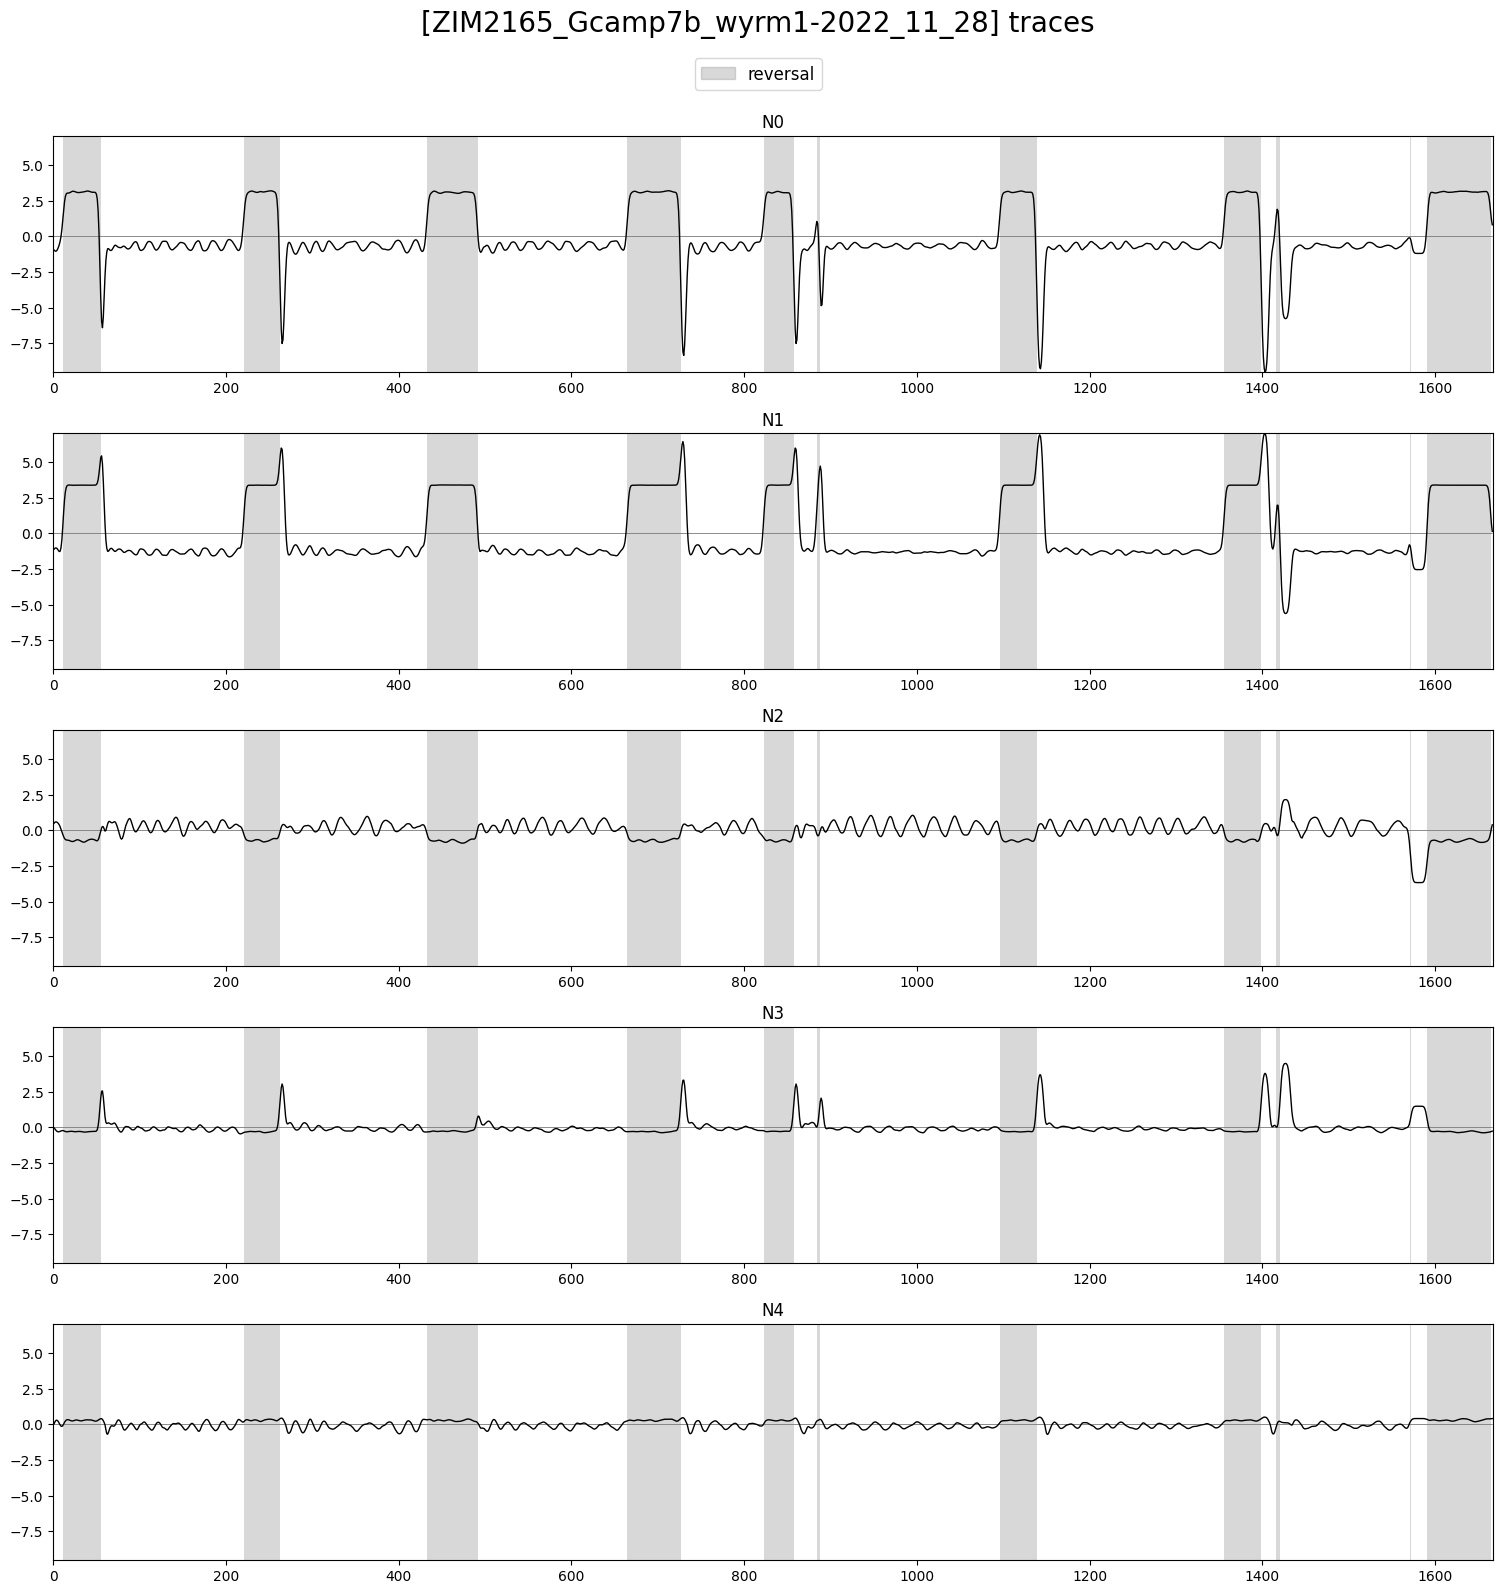

In [51]:
plot_utils.plot_traces(traces[neuron_labels],
					   discrete_states[['REV']],
					   label='reversal',
					   title=f'[{filename}] traces', ylimits=None, plots_per_row=1)